# 01 — Band-power cross-dataset classification (Experiment 1, revised)

**Question 1.** Can a logistic regression classifier developed using Dataset 1 reliably distinguish first-episode psychosis from controls in held-out Dataset 2, with ROC-AUC above chance and balanced performance across both groups?

- **Primary hypothesis:** Dataset 2 ROC-AUC > 0.50.
- **Secondary measures:** balanced accuracy (chance = 0.50), sensitivity and specificity, at a fixed threshold of 0.50.

**Why this is a revision.** The original Experiment 1 used fixed settings (C = 1, no class weighting) and reported a Dataset 2 ROC-AUC of 0.476 (95% CI 0.262–0.684). That notebook and its outputs are archived unchanged in `outputs/archive_experiment_1_original_2026-11-16_125350_EST/`. This revision chooses the regularization strength and class weighting using Dataset 1 only. **Dataset 2 results were already seen in the original experiment, so this is a revised exploratory analysis, not a first external validation.** Keeping Dataset 2 out of model selection here does not undo that earlier exposure. The original and revised methods are not compared to choose a winner by test AUC.

**Data.** The frozen 110-participant preprocessing in `outputs/frozen_preprocessing_2026-11-16_124625_EST/`: Dataset 1 (Task 1, `ds003944`) has 75 participants for model development, and Dataset 2 (Task 2, `ds003947`) has 35 for testing. The predictors are `relative_delta`, `relative_theta`, `relative_alpha` and `relative_beta` only. No participant ID appears in both datasets, but person-level independence is unconfirmed, and Dataset 1 includes ten documented acquisition-2 participants.

**Sensitivity check.** The same procedure is repeated on the original 107-participant preprocessing (74 / 33). The 110-participant version stays primary.

**Scope.** This notebook answers Question 1 only. Internal-versus-external performance is Question 2.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, balanced_accuracy_score,
                             recall_score, f1_score, confusion_matrix)
from IPython.display import display, Markdown

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "outputs").is_dir() and (p / "data").is_dir())
FROZEN = PROJECT / "outputs/frozen_preprocessing_2026-11-16_124625_EST"
BASELINE = PROJECT / "outputs/baseline_2026-11-10_145427_EST"
ORIGINAL_EXPERIMENT = PROJECT / "outputs/archive_experiment_1_original_2026-11-16_125350_EST"
OUTPUT = PROJECT / "outputs/experiment_1_revised"
OUTPUT.mkdir(parents=True, exist_ok=True)

FEATURES = ["relative_delta", "relative_theta", "relative_alpha", "relative_beta"]
LABEL_CODES = {"Control": 0, "Psychosis": 1}  # source label "Psychosis" = first-episode psychosis
TRAIN_DATASET, TEST_DATASET = "resting-task-1", "resting-task-2"
C_VALUES = [0.1, 1, 10]
CLASS_WEIGHTS = [None, "balanced"]
N_FOLDS = 5
THRESHOLD = 0.50
N_BOOTSTRAP = 5000
RANDOM_SEED = 270
print("Python", platform.python_version(), "| scikit-learn", version("scikit-learn"))

Python 3.14.7 | scikit-learn 1.9.1


## 1. Load the frozen inputs and check them

Each input file is checked against the SHA-256 manifest of its snapshot. For each version, the notebook then checks:
- one row per participant, and no shared IDs between datasets;
- only `Control`/`Psychosis` labels, with both groups present;
- the same four finite numeric features;
- feature rows identical to the included participants (and their diagnoses) in the frozen `participant_qc.csv`;
- the exact expected group counts.

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def check_manifest(folder, files):
    manifest = json.loads((folder / "sha256_manifest.json").read_text())
    hashes = manifest.get("sha256", manifest)  # the baseline manifest is a flat {file: hash} map
    for name in files:
        assert sha256(folder / name) == hashes[name], f"{folder.name}/{name} does not match its manifest"
    return {f"{folder.name}/{name}": hashes[name] for name in files}


def load_version(folder, expected_counts):
    files = [f"master_preprocessing/{TRAIN_DATASET}_features.csv",
             f"master_preprocessing/{TEST_DATASET}_features.csv",
             "master_preprocessing/participant_qc.csv"]
    hashes = check_manifest(folder, files)
    train, test, qc = (pd.read_csv(folder / name) for name in files)
    for name, table in [(TRAIN_DATASET, train), (TEST_DATASET, test)]:
        assert table.dataset.eq(name).all()
        assert not table.participant_id.duplicated().any(), f"{name}: duplicate participant rows"
        assert set(table.diagnosis) == set(LABEL_CODES), f"{name}: unexpected or missing diagnosis label"
        assert all(pd.api.types.is_numeric_dtype(table[c]) for c in FEATURES)
        assert np.isfinite(table[FEATURES].to_numpy()).all(), f"{name}: non-finite feature"
        included = qc[(qc.dataset == name) & qc.included].set_index("participant_id")
        assert set(table.participant_id) == set(included.index), f"{name}: rows differ from QC inclusion"
        assert (table.set_index("participant_id").diagnosis == included.diagnosis.loc[table.participant_id]).all()
        assert {"participants": len(table), **table.diagnosis.value_counts().to_dict()} == expected_counts[name]
    assert not set(train.participant_id) & set(test.participant_id), "participant IDs overlap"
    return {"train": train, "test": test, "input_sha256": hashes}


versions = {
    "primary_110": load_version(FROZEN, {
        TRAIN_DATASET: {"participants": 75, "Control": 29, "Psychosis": 46},
        TEST_DATASET: {"participants": 35, "Control": 14, "Psychosis": 21}}),
    "sensitivity_baseline_107": load_version(BASELINE, {
        TRAIN_DATASET: {"participants": 74, "Control": 29, "Psychosis": 45},
        TEST_DATASET: {"participants": 33, "Control": 14, "Psychosis": 19}}),
}
display(pd.DataFrame([{"analysis": a, "dataset": d, **v[part].diagnosis.value_counts().to_dict(), "total": len(v[part])}
                      for a, v in versions.items() for part, d in [("train", TRAIN_DATASET), ("test", TEST_DATASET)]]))

,analysis,dataset,Psychosis,Control,total
0,primary_110,resting-task-1,46,29,75
1,primary_110,resting-task-2,21,14,35
2,sensitivity_baseline_107,resting-task-1,45,29,74
3,sensitivity_baseline_107,resting-task-2,19,14,33


## 2. Model selection using Dataset 1 only

The model is a pipeline of `StandardScaler` and L2 logistic regression (`solver="lbfgs"`, `max_iter=1000`; in scikit-learn 1.9 pure L2 is written `l1_ratio=0.0`). The candidate grid is fixed in advance and will not be expanded: **C ∈ {0.1, 1, 10} × class_weight ∈ {None, "balanced"}**, six candidates in total.

Each candidate is scored by mean ROC-AUC over the same shuffled, stratified 5-fold split of Dataset 1 (seed 270). `cross_val_score` refits the whole pipeline in every fold, so the scaler only ever sees that fold's training part.

**Tie-breaking rule (fixed before running):** choose the highest mean AUC rounded to 10 decimals. If tied, choose the smaller C (stronger regularization). If still tied, choose `class_weight=None` over `"balanced"`.

The four relative powers sum to one, so they are not independent. Regularization is always kept, and coefficients are not interpreted as separate biological effects.

In [3]:
def make_model(C, class_weight):
    return Pipeline([
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(l1_ratio=0.0, C=C, class_weight=class_weight,
                                        solver="lbfgs", max_iter=1000)),
    ])


def features_and_labels(table):
    return table[FEATURES].to_numpy(), table.diagnosis.map(LABEL_CODES).to_numpy()


def select_settings(train):
    X, y = features_and_labels(train)
    folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    rows = []
    for C in C_VALUES:
        for class_weight in CLASS_WEIGHTS:
            scores = cross_val_score(make_model(C, class_weight), X, y, cv=folds, scoring="roc_auc")
            rows.append({"C": C, "class_weight": str(class_weight), "mean_cv_auc": scores.mean(),
                         "sd_cv_auc": scores.std(ddof=1), **{f"fold_{i+1}_auc": s for i, s in enumerate(scores)}})
    table = pd.DataFrame(rows)
    order = table.assign(rounded=table.mean_cv_auc.round(10), weighted=table.class_weight.ne("None"))
    best = order.sort_values(["rounded", "C", "weighted"], ascending=[False, True, True]).iloc[0]

    # Check: refitting by hand on each fold's training part reproduces the selected candidate's fold scores.
    chosen_weight = None if best.class_weight == "None" else best.class_weight
    by_hand = [roc_auc_score(y[test], make_model(best.C, chosen_weight).fit(X[fit], y[fit]).predict_proba(X[test])[:, 1])
               for fit, test in folds.split(X, y)]
    assert np.allclose(by_hand, best[[f"fold_{i+1}_auc" for i in range(N_FOLDS)]].astype(float))
    return table, {"C": float(best.C), "class_weight": chosen_weight, "mean_cv_auc": float(best.mean_cv_auc)}


selection = {analysis: select_settings(v["train"]) for analysis, v in versions.items()}
for analysis, (table, chosen) in selection.items():
    print(f"{analysis}: selected C = {chosen['C']}, class_weight = {chosen['class_weight']}")
    display(table[["C", "class_weight", "mean_cv_auc", "sd_cv_auc"]].round(3))

primary_110: selected C = 0.1, class_weight = None


,C,class_weight,mean_cv_auc,sd_cv_auc
0,0.1,None,0.635,0.089
1,0.1,balanced,0.631,0.083
2,1.0,None,0.627,0.078
3,1.0,balanced,0.627,0.078
4,10.0,None,0.627,0.078
5,10.0,balanced,0.627,0.078


sensitivity_baseline_107: selected C = 10.0, class_weight = None


,C,class_weight,mean_cv_auc,sd_cv_auc
0,0.1,None,0.598,0.135
1,0.1,balanced,0.598,0.135
2,1.0,None,0.595,0.146
3,1.0,balanced,0.595,0.146
4,10.0,None,0.603,0.138
5,10.0,balanced,0.599,0.144


## 3. Lock the selected settings

The cross-validation scores and selected settings are saved **before** any revised Dataset 2 performance is calculated. The final models are then built from the saved file, not from variables in memory.

In [4]:
pd.concat([t.assign(analysis_version=a) for a, (t, _) in selection.items()]).to_csv(
    OUTPUT / "training_cv_scores.csv", index=False)
locked = {"selection_rule": "highest mean 5-fold CV ROC-AUC (rounded to 10 decimals); ties -> smaller C, then class_weight None",
          "grid": {"C": C_VALUES, "class_weight": [str(w) for w in CLASS_WEIGHTS]},
          "cv": f"StratifiedKFold(n_splits={N_FOLDS}, shuffle=True, random_state={RANDOM_SEED}) on Dataset 1 only",
          "threshold": THRESHOLD,
          "selected": {a: chosen for a, (_, chosen) in selection.items()}}
(OUTPUT / "selected_settings.json").write_text(json.dumps(locked, indent=2) + "\n")
locked = json.loads((OUTPUT / "selected_settings.json").read_text())  # build the final models from the saved file
print(json.dumps(locked["selected"], indent=2))

{
  "primary_110": {
    "C": 0.1,
    "class_weight": null,
    "mean_cv_auc": 0.6351111111111111
  },
  "sensitivity_baseline_107": {
    "C": 10.0,
    "class_weight": null,
    "mean_cv_auc": 0.6029629629629629
  }
}


## 4. Dataset 2 evaluation

Each locked pipeline is fitted on all of its Dataset 1 participants and applied unchanged to Dataset 2.

- **Primary:** ROC-AUC with a 95% percentile interval from 5,000 stratified bootstrap resamples of Dataset 2 participants (seed 270). Controls and patients are each resampled with replacement within their own group, using the fixed predicted probabilities, and the model is never refitted. The interval shows uncertainty from which test participants were sampled, given the fitted model. It leaves out uncertainty from the training sample and from model selection.
- **Secondary (threshold 0.50):** balanced accuracy, accuracy, sensitivity, specificity, F1 (psychosis) and the confusion matrix. The benchmark is always predicting the Dataset 1 majority class (Psychosis); applied to Dataset 2 it gives the accuracy shown, with balanced accuracy 0.50. High sensitivity alone is not success.

In [5]:
def fit_and_predict(analysis, train, test, settings):
    X_train, y_train = features_and_labels(train)
    X_test, y_test = features_and_labels(test)
    model = make_model(settings["C"], settings["class_weight"]).fit(X_train, y_train)
    scaler = model.named_steps["scale"]
    assert np.allclose(scaler.mean_, X_train.mean(axis=0)) and np.allclose(scaler.scale_, X_train.std(axis=0))
    assert list(model.classes_) == [0, 1]
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    predictions = pd.DataFrame({
        "analysis_version": analysis, "dataset": TEST_DATASET, "participant_id": test.participant_id.to_numpy(),
        "diagnosis": test.diagnosis.to_numpy(), "true_label": y_test, "probability_psychosis": probability,
        "predicted_label": (probability >= THRESHOLD).astype(int)})
    assert predictions.participant_id.tolist() == test.participant_id.tolist()
    return model, predictions


def bootstrap_auc_interval(y_true, probability):
    rng = np.random.default_rng(RANDOM_SEED)
    controls, patients = np.flatnonzero(y_true == 0), np.flatnonzero(y_true == 1)
    aucs = [roc_auc_score(y_true[s], probability[s]) for s in
            (np.concatenate([rng.choice(controls, len(controls)), rng.choice(patients, len(patients))])
             for _ in range(N_BOOTSTRAP))]
    return np.percentile(aucs, [2.5, 97.5])


def test_metrics(analysis, train, predictions, settings):
    y, p, yhat = (predictions[c].to_numpy() for c in ["true_label", "probability_psychosis", "predicted_label"])
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    assert tn + fp == (y == 0).sum() and fn + tp == (y == 1).sum()
    low, high = bootstrap_auc_interval(y, p)
    majority_label = LABEL_CODES[train.diagnosis.value_counts().idxmax()]
    sensitivity, specificity = tp / (tp + fn), tn / (tn + fp)
    assert np.isclose(sensitivity, recall_score(y, yhat, pos_label=1))
    assert np.isclose(balanced_accuracy_score(y, yhat), (sensitivity + specificity) / 2)
    return {"analysis_version": analysis, "C": settings["C"], "class_weight": str(settings["class_weight"]),
            "train_n": len(train), "train_control": int((train.diagnosis == "Control").sum()),
            "train_psychosis": int((train.diagnosis == "Psychosis").sum()),
            "test_n": len(y), "test_control": int((y == 0).sum()), "test_psychosis": int((y == 1).sum()),
            "roc_auc": roc_auc_score(y, p), "roc_auc_ci_low": low, "roc_auc_ci_high": high,
            "ci_includes_0.5": bool(low <= 0.5 <= high),
            "balanced_accuracy": balanced_accuracy_score(y, yhat), "accuracy": accuracy_score(y, yhat),
            "sensitivity": sensitivity, "specificity": specificity,
            "f1_psychosis": f1_score(y, yhat, pos_label=1, zero_division=0),
            "majority_class_accuracy": float((y == majority_label).mean()), "majority_class_balanced_accuracy": 0.5,
            "true_negative": tn, "false_positive": fp, "false_negative": fn, "true_positive": tp}


results = {}
for analysis, v in versions.items():
    model, predictions = fit_and_predict(analysis, v["train"], v["test"], locked["selected"][analysis])
    results[analysis] = (model, predictions, test_metrics(analysis, v["train"], predictions, locked["selected"][analysis]))
metrics = pd.DataFrame([m for _, _, m in results.values()])
display(metrics.set_index("analysis_version").T)

analysis_version,primary_110,sensitivity_baseline_107
C,0.1,10.0
class_weight,None,None
train_n,75,74
train_control,29,29
train_psychosis,46,45
test_n,35,33
test_control,14,14
test_psychosis,21,19
roc_auc,0.496599,0.481203
roc_auc_ci_low,0.289116,0.270677


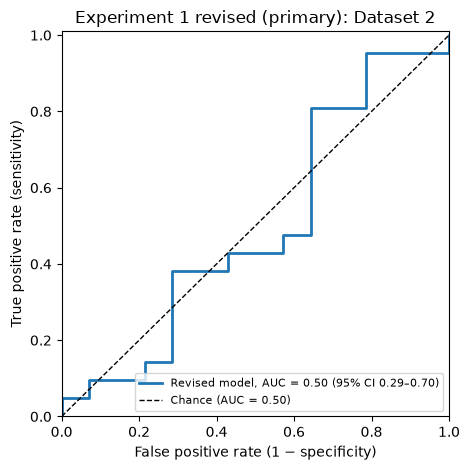

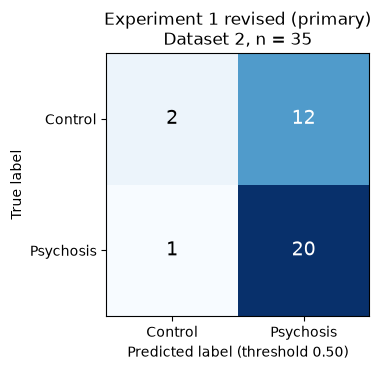

In [6]:
primary = results["primary_110"][1]
row = metrics.set_index("analysis_version").loc["primary_110"]
fpr, tpr, _ = roc_curve(primary.true_label, primary.probability_psychosis)

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot(fpr, tpr, lw=2, label=f"Revised model, AUC = {row.roc_auc:.2f} (95% CI {row.roc_auc_ci_low:.2f}–{row.roc_auc_ci_high:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.50)")
ax.set(xlabel="False positive rate (1 − specificity)", ylabel="True positive rate (sensitivity)",
       title="Experiment 1 revised (primary): Dataset 2", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "primary_roc_curve.png", dpi=150)
plt.show()

matrix = confusion_matrix(primary.true_label, primary.predicted_label, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(matrix, cmap="Blues")
for (i, j), n in np.ndenumerate(matrix):
    ax.text(j, i, n, ha="center", va="center", fontsize=14, color="white" if n > matrix.max() / 2 else "black")
ax.set_xticks([0, 1], ["Control", "Psychosis"])
ax.set_yticks([0, 1], ["Control", "Psychosis"])
ax.set(xlabel="Predicted label (threshold 0.50)", ylabel="True label",
       title=f"Experiment 1 revised (primary)\nDataset 2, n = {matrix.sum()}")
fig.tight_layout()
fig.savefig(OUTPUT / "primary_confusion_matrix.png", dpi=150)
plt.show()

## 5. Save outputs and summary

The original experiment's metrics are read from the verified archive and shown next to the revised ones **for the record only**. Neither method is preferred because of its test AUC. The primary and sensitivity versions differ in both training and test participants, so a difference between them is not a clean test of channel omission. The summary text is generated from the computed numbers.

In [7]:
archive = json.loads((ORIGINAL_EXPERIMENT / "sha256_manifest.json").read_text())["sha256"]
assert sha256(ORIGINAL_EXPERIMENT / "experiment_1/metrics.csv") == archive["experiment_1/metrics.csv"]
original = pd.read_csv(ORIGINAL_EXPERIMENT / "experiment_1/metrics.csv").set_index("analysis_version")

pd.concat([p for _, p, _ in results.values()]).to_csv(OUTPUT / "test_predictions.csv", index=False)
metrics.to_csv(OUTPUT / "test_metrics.csv", index=False)
settings = {"question": "Question 1: Dataset 1-developed logistic regression on held-out Dataset 2",
            "status": "revised exploratory analysis; Dataset 2 results were seen in the original experiment",
            "features": FEATURES, "label_codes": LABEL_CODES, **{k: locked[k] for k in ["grid", "cv", "selection_rule", "selected"]},
            "pipeline": "StandardScaler -> LogisticRegression(l1_ratio=0.0 [L2], solver='lbfgs', max_iter=1000, C, class_weight)",
            "threshold": THRESHOLD,
            "bootstrap": {"resamples": N_BOOTSTRAP, "stratified_by": "diagnosis", "random_seed": RANDOM_SEED,
                          "interval": "percentile 2.5-97.5 of test AUC; fixed predictions; no refitting"},
            "standardized_coefficients_not_independent_effects": {
                a: dict(zip(FEATURES, m.named_steps["logistic"].coef_[0])) for a, (m, _, _) in results.items()},
            "input_sha256": {a: v["input_sha256"] for a, v in versions.items()},
            "versions": {"python": platform.python_version(),
                         **{p: version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]}}}
(OUTPUT / "experiment_settings.json").write_text(json.dumps(settings, indent=2, default=float) + "\n")


def describe(r):
    if r["ci_includes_0.5"]:
        verdict = "The interval includes 0.50, so above-chance discrimination is not supported."
    elif r.roc_auc_ci_low > 0.5:
        verdict = "The interval lies above 0.50, which supports above-chance discrimination in this test sample."
    else:
        verdict = "The interval lies below 0.50 (worse than chance in this test sample)."
    return (f"Selected C = {r.C:g}, class_weight = {r.class_weight}. Dataset 2 ROC-AUC = {r.roc_auc:.3f} "
            f"(95% CI {r.roc_auc_ci_low:.3f}–{r.roc_auc_ci_high:.3f}; n = {r.test_n}: {r.test_control} controls, "
            f"{r.test_psychosis} psychosis). {verdict} At threshold 0.50: balanced accuracy {r.balanced_accuracy:.3f} "
            f"(chance 0.50), accuracy {r.accuracy:.3f} (always predicting the training majority class: "
            f"{r.majority_class_accuracy:.3f}), sensitivity {r.sensitivity:.3f}, specificity {r.specificity:.3f}, "
            f"F1 {r.f1_psychosis:.3f} (TN {r.true_negative}, FP {r.false_positive}, FN {r.false_negative}, TP {r.true_positive}).")


m = metrics.set_index("analysis_version")
same = m["ci_includes_0.5"].nunique() == 1
comparison = pd.DataFrame({
    "original (C=1, no weighting)": original.loc["primary_110", ["roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "sensitivity", "specificity"]],
    "revised (CV-selected)": m.loc["primary_110", ["roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "sensitivity", "specificity"]]}).astype(float)
display(comparison.round(3))
summary = "\n".join([
    "# Experiment 1 (revised) results summary", "",
    "Revised exploratory analysis: Dataset 2 results had already been seen in the original Experiment 1, so this is not a first external validation.",
    "Settings were chosen by 5-fold cross-validation within Dataset 1 only, saved, and then tested once on Dataset 2.", "",
    "## Primary analysis (frozen 110-participant preprocessing)", describe(m.loc["primary_110"]), "",
    "## Sensitivity analysis (original 107-participant preprocessing)", describe(m.loc["sensitivity_baseline_107"]), "",
    ("The conclusion about chance-level discrimination is the same in both versions." if same
     else "The conclusion about chance-level discrimination differs between versions."),
    "Training and test membership both differ between versions, so this is not an isolated test of channel omission. "
    "The 110-participant version remains primary.", "",
    "## Original experiment, for the record",
    f"Original (fixed C = 1, no class weighting): ROC-AUC {original.loc['primary_110', 'roc_auc']:.3f} "
    f"(95% CI {original.loc['primary_110', 'roc_auc_ci_low']:.3f}–{original.loc['primary_110', 'roc_auc_ci_high']:.3f}, "
    "2,000 resamples). Archived unchanged; not replaced on the basis of test performance.", "",
    "## Limitations",
    "- The CI reflects test-sample uncertainty only, not training or model-selection uncertainty.",
    "- Dataset 2 was seen before this revision; small test set (35, with 14 controls).",
    "- Uneven exclusions (Dataset 1 8.5%, Dataset 2 42.6%); three recovered participants use 48 instead of 49 channels.",
    "- No shared IDs, but person-level independence is unconfirmed; Dataset 1 includes ten acquisition-2 participants.",
    "- The four relative powers sum to one; coefficients are not independent biological effects.",
    "- Research analysis only, not a clinically validated diagnostic tool.",
])
(OUTPUT / "results_summary.md").write_text(summary + "\n")
display(Markdown(summary))

,"original (C=1, no weighting)",revised (CV-selected)
roc_auc,0.476,0.497
roc_auc_ci_low,0.262,0.289
roc_auc_ci_high,0.684,0.704
sensitivity,0.810,0.952
specificity,0.214,0.143


# Experiment 1 (revised) results summary

Revised exploratory analysis: Dataset 2 results had already been seen in the original Experiment 1, so this is not a first external validation.
Settings were chosen by 5-fold cross-validation within Dataset 1 only, saved, and then tested once on Dataset 2.

## Primary analysis (frozen 110-participant preprocessing)
Selected C = 0.1, class_weight = None. Dataset 2 ROC-AUC = 0.497 (95% CI 0.289–0.704; n = 35: 14 controls, 21 psychosis). The interval includes 0.50, so above-chance discrimination is not supported. At threshold 0.50: balanced accuracy 0.548 (chance 0.50), accuracy 0.629 (always predicting the training majority class: 0.600), sensitivity 0.952, specificity 0.143, F1 0.755 (TN 2, FP 12, FN 1, TP 20).

## Sensitivity analysis (original 107-participant preprocessing)
Selected C = 10, class_weight = None. Dataset 2 ROC-AUC = 0.481 (95% CI 0.271–0.684; n = 33: 14 controls, 19 psychosis). The interval includes 0.50, so above-chance discrimination is not supported. At threshold 0.50: balanced accuracy 0.547 (chance 0.50), accuracy 0.576 (always predicting the training majority class: 0.576), sensitivity 0.737, specificity 0.357, F1 0.667 (TN 5, FP 9, FN 5, TP 14).

The conclusion about chance-level discrimination is the same in both versions.
Training and test membership both differ between versions, so this is not an isolated test of channel omission. The 110-participant version remains primary.

## Original experiment, for the record
Original (fixed C = 1, no class weighting): ROC-AUC 0.476 (95% CI 0.262–0.684, 2,000 resamples). Archived unchanged; not replaced on the basis of test performance.

## Limitations
- The CI reflects test-sample uncertainty only, not training or model-selection uncertainty.
- Dataset 2 was seen before this revision; small test set (35, with 14 controls).
- Uneven exclusions (Dataset 1 8.5%, Dataset 2 42.6%); three recovered participants use 48 instead of 49 channels.
- No shared IDs, but person-level independence is unconfirmed; Dataset 1 includes ten acquisition-2 participants.
- The four relative powers sum to one; coefficients are not independent biological effects.
- Research analysis only, not a clinically validated diagnostic tool.